Will made some flares. Spot check them.

In [1]:
import os
import numpy as np
import pandas as pd
import glob
import RTModel.plotmodel as plm
import matplotlib.pyplot as plt
from scipy.optimize import lsq_linear
import VBMicrolensing

In [2]:
%pip install datasets pandas pyarrow duckdb huggingface_hub


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
from datasets import load_dataset
import os

os.environ["HF_TOKEN"] = "hf_your_token_here" # generate your own huggingface token if you are planning to run tons of events; for now, this is fine as-is

token = os.environ.get("HF_TOKEN")
assert token, "Set HF_TOKEN environment variable first"

dataset_name = "derocco/GULLSFlares"

# Load metadata and epochs tables (which fit easily in RAM)
meta_df = load_dataset(dataset_name, "metadata", split="train", token=token).to_pandas()
epochs_df = load_dataset(dataset_name, "epochs", split="train", token=token).to_pandas()

print(f"Metadata     : {meta_df.shape[0]:,} rows")
print(f"Epochs       : {epochs_df.shape[0]:,} rows")

ML_Flare_meta.parquet: reconstructing file:   0%|          |  0.00B / 4.57MB            

ML_Flare_meta.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3562 [00:00<?, ? examples/s]

ML_Flare_epoch.parquet: reconstructing file:   0%|          |  0.00B / 3.57MB            

ML_Flare_epoch.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/98974 [00:00<?, ? examples/s]

Metadata     : 3,562 rows
Epochs       : 98,974 rows


In [9]:
meta_df.event_id

0        -6001
1        -6002
2        -6225
3        -6226
4        -6257
         ...  
3557   -565378
3558   -568179
3559   -568180
3560   -582799
3561   -582800
Name: event_id, Length: 3562, dtype: int64

why the event ids negative? oh well

In [32]:
meta_df.parent_event_id

0         3000
1         3000
2         3112
3         3112
4         3128
         ...  
3557    282688
3558    284089
3559    284089
3560    291399
3561    291399
Name: parent_event_id, Length: 3562, dtype: int64

i c. now what are the different flare sizes?

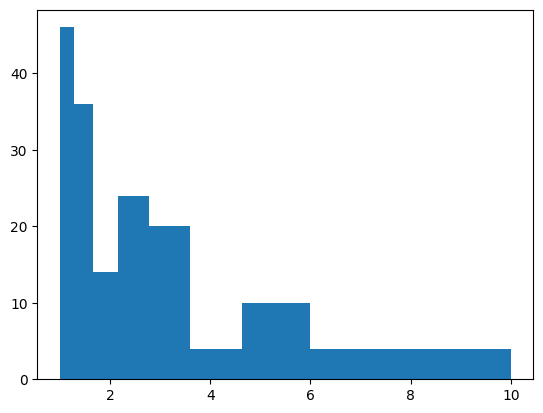

In [45]:
plt.hist(meta_df.peak_excess_uJy/meta_df.baseline_flux_uJy, bins=np.logspace(0,1,10))
plt.show()

### tall flare

In [24]:
import duckdb
from huggingface_hub import HfFileSystem
import os

token = os.environ.get("HF_TOKEN")
con = duckdb.connect()
con.register_filesystem(HfFileSystem(token=token))

obs_p = "hf://datasets/derocco/GULLSFlares/ML_Flare_obs.parquet"
meta_p = "hf://datasets/derocco/GULLSFlares/ML_Flare_meta.parquet"
epoch_p = "hf://datasets/derocco/GULLSFlares/ML_Flare_epoch.parquet"

event_id = 3000

# Reconstruct a single event's lightcurve
event_obs = con.execute(f"""
    SELECT 
        o.event_id,
        m.name,
        e.bjd,
        o.filt,
        o.flux_uJy,
        o.flux_err_uJy,
        m.tE_helio,
        m.sim_label,
        m.flare_model,
        m.parent_event_id,
        m.baseline_flux_uJy,
        m.peak_excess_uJy,
        m.peak_bjd,
        m.fwhm_days
    FROM '{obs_p}' o
    JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
    JOIN '{meta_p}' m ON o.event_id = m.event_id
    WHERE o.parent_event_id = {event_id}
    ORDER BY e.bjd
""").df()

print(f"Event {event_id}: {event_obs['name'].iloc[0]} ({event_obs['sim_label'].iloc[0]})")
print(f"  {len(event_obs):,} observations")
print(f"  Einstein timescale tE_helio = {abs(event_obs['tE_helio'].iloc[0]):.2f} days")


Event 3000: RMDC26_003000__flare_pitkin (RMDC26_1S1L_ML)
  92,976 observations
  Einstein timescale tE_helio = 3.55 days


In [25]:
event_obs

,event_id,name,bjd,filt,flux_uJy,flux_err_uJy,tE_helio,sim_label,flare_model,parent_event_id,baseline_flux_uJy,peak_excess_uJy,peak_bjd,fwhm_days
0,-6002,RMDC26_003000__flare_pitkin,2.461448e+06,F146,2.797227,0.130734,3.553733,RMDC26_1S1L_ML,pitkin,3000,2.556952,0.03471,2.462736e+06,10.155536
1,-6001,RMDC26_003000__flare_davenport,2.461448e+06,F146,2.797227,0.130734,3.553733,RMDC26_1S1L_ML,davenport,3000,2.556952,0.03471,2.462736e+06,10.155536
2,-6002,RMDC26_003000__flare_pitkin,2.461448e+06,F146,2.508089,0.130734,3.553733,RMDC26_1S1L_ML,pitkin,3000,2.556952,0.03471,2.462736e+06,10.155536
3,-6001,RMDC26_003000__flare_davenport,2.461448e+06,F146,2.508089,0.130734,3.553733,RMDC26_1S1L_ML,davenport,3000,2.556952,0.03471,2.462736e+06,10.155536
4,-6002,RMDC26_003000__flare_pitkin,2.461448e+06,F146,2.517673,0.130734,3.553733,RMDC26_1S1L_ML,pitkin,3000,2.556952,0.03471,2.462736e+06,10.155536
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92971,-6001,RMDC26_003000__flare_davenport,2.463164e+06,F146,2.462295,0.130734,3.553733,RMDC26_1S1L_ML,davenport,3000,2.556952,0.03471,2.462736e+06,10.155536
92972,-6002,RMDC26_003000__flare_pitkin,2.463164e+06,F146,2.675821,0.130734,3.553733,RMDC26_1S1L_ML,pitkin,3000,2.556952,0.03471,2.462736e+06,10.155536
92973,-6001,RMDC26_003000__flare_davenport,2.463164e+06,F146,2.675821,0.130734,3.553733,RMDC26_1S1L_ML,davenport,3000,2.556952,0.03471,2.462736e+06,10.155536
92974,-6002,RMDC26_003000__flare_pitkin,2.463164e+06,F146,2.602870,0.130734,3.553733,RMDC26_1S1L_ML,pitkin,3000,2.556952,0.03471,2.462736e+06,10.155536


In [26]:
event_obs_davenport = event_obs.loc[event_obs['flare_model']=='davenport']
event_obs_pitkin = event_obs.loc[event_obs['flare_model']=='pitkin']

flux excess ratio, davenport:  0.013574934127815245
flux excess ratio, pitkin:  0.013574934127815245


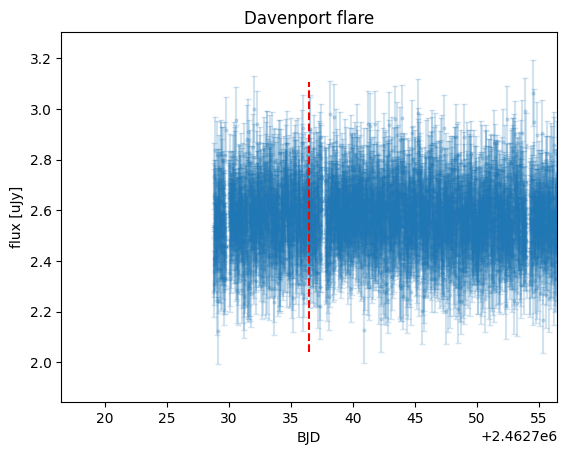

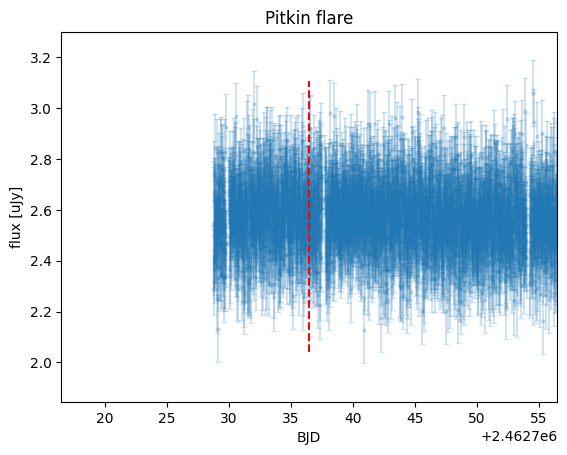

In [42]:
print("flux excess ratio, davenport: ", event_obs_davenport['peak_excess_uJy'].iloc[0]/event_obs_davenport['baseline_flux_uJy'].iloc[0])
print("flux excess ratio, pitkin: ", event_obs_pitkin['peak_excess_uJy'].iloc[0]/event_obs_pitkin['baseline_flux_uJy'].iloc[0])

plt.errorbar(event_obs_davenport['bjd'], event_obs_davenport['flux_uJy'], event_obs_davenport['flux_err_uJy'], 
             linestyle='', marker='o', markersize=2, capsize=2, alpha=0.2)
plt.xlabel('BJD')
plt.ylabel('flux [uJy]')
plt.xlim([event_obs['peak_bjd'].iloc[0]-20, event_obs['peak_bjd'].iloc[0]+20])
plt.vlines(event_obs['peak_bjd'].iloc[0], min(event_obs['flux_uJy']), max(event_obs['flux_uJy']), linestyle='--', color='r',
          zorder=100)
plt.title('Davenport flare')
plt.show()

plt.errorbar(event_obs_pitkin['bjd'], event_obs_pitkin['flux_uJy'], event_obs_pitkin['flux_err_uJy'], 
             linestyle='', marker='o', markersize=2, capsize=2, alpha=0.2)
plt.xlabel('BJD')
plt.ylabel('flux [uJy]')
plt.xlim([event_obs['peak_bjd'].iloc[0]-20, event_obs['peak_bjd'].iloc[0]+20])
plt.vlines(event_obs['peak_bjd'].iloc[0], min(event_obs['flux_uJy']), max(event_obs['flux_uJy']), linestyle='--', color='r',
          zorder=100)
plt.title('Pitkin flare')
plt.show()

### grande flare

In [51]:
meta_df.loc[(meta_df.peak_excess_uJy/meta_df.baseline_flux_uJy > 0.25) & (meta_df.peak_excess_uJy/meta_df.baseline_flux_uJy < 0.5)]


,name,event_id,sim_label,SubRun,Field,EventID,final_weight,ObsGroup_0_chi2,t0lens1,tE_ref,...,extinction_F087,extinction_F213,parent_event_id,flare_model,parent_name,parameter_quality,baseline_flux_uJy,peak_excess_uJy,peak_bjd,fwhm_days
42,RMDC26_004776__flare_davenport,-9553,RMDC26_1S1L_ML,1.0,600.0,8049.0,0.009797,2.510492e+05,2.461516e+06,0.170967,...,0.625870,0.084157,4776,davenport,RMDC26_004776,approximate_pass,218.295872,55.170434,2.461516e+06,0.201587
43,RMDC26_004776__flare_pitkin,-9554,RMDC26_1S1L_ML,1.0,600.0,8049.0,0.009797,2.510492e+05,2.461516e+06,0.170967,...,0.625870,0.084157,4776,pitkin,RMDC26_004776,approximate_pass,218.295872,55.170434,2.461516e+06,0.201587
54,RMDC26_005112__flare_davenport,-10225,RMDC26_1S1L_ML,0.0,86.0,9614.0,0.009875,1.890530e+04,2.461675e+06,0.408124,...,1.788201,0.240450,5112,davenport,RMDC26_005112,approximate_pass,22.099254,5.887889,2.461675e+06,0.180266
55,RMDC26_005112__flare_pitkin,-10226,RMDC26_1S1L_ML,0.0,86.0,9614.0,0.009875,1.890530e+04,2.461675e+06,0.408124,...,1.788201,0.240450,5112,pitkin,RMDC26_005112,approximate_pass,22.099254,5.887889,2.461675e+06,0.180266
56,RMDC26_005192__flare_davenport,-10385,RMDC26_1S1L_ML,0.0,22.0,2466.0,0.028505,5.110135e+02,2.463146e+06,0.494907,...,7.129975,0.958729,5192,davenport,RMDC26_005192,approximate_pass,1.103086,0.329159,2.463146e+06,0.654670
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3475,RMDC26_121688__flare_pitkin,-243378,RMDC26_1S1L_ML,2.0,591.0,8038.0,0.021356,5.626881e+06,2.461838e+06,1.475184,...,7.947981,1.068722,121688,pitkin,RMDC26_121688,approximate_pass,277.569816,82.078710,2.461838e+06,2.956625
3506,RMDC26_027565__flare_davenport,-55131,RMDC26_1S1L_ML,1.0,838.0,260.0,0.004790,1.017991e+05,2.462778e+06,0.846309,...,0.778058,0.104621,27565,davenport,RMDC26_027565,approximate_pass,12.960849,6.454362,2.462778e+06,0.690399
3507,RMDC26_027565__flare_pitkin,-55132,RMDC26_1S1L_ML,1.0,838.0,260.0,0.004790,1.017991e+05,2.462778e+06,0.846309,...,0.778058,0.104621,27565,pitkin,RMDC26_027565,approximate_pass,12.960849,6.454362,2.462778e+06,0.690399
3534,RMDC26_169926__flare_davenport,-339853,RMDC26_1S1L_ML,0.0,914.0,1787.0,0.011046,8.381331e+03,2.461827e+06,0.401292,...,2.473043,0.332537,169926,davenport,RMDC26_169926,approximate_pass,7.464541,1.908965,2.461827e+06,0.536192


In [52]:
event_id = 4776

# Reconstruct a single event's lightcurve
event_obs = con.execute(f"""
    SELECT 
        o.event_id,
        m.name,
        e.bjd,
        o.filt,
        o.flux_uJy,
        o.flux_err_uJy,
        m.tE_helio,
        m.sim_label,
        m.flare_model,
        m.parent_event_id,
        m.baseline_flux_uJy,
        m.peak_excess_uJy,
        m.peak_bjd,
        m.fwhm_days
    FROM '{obs_p}' o
    JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
    JOIN '{meta_p}' m ON o.event_id = m.event_id
    WHERE o.parent_event_id = {event_id}
    ORDER BY e.bjd
""").df()

flux excess ratio, davenport:  0.2527323768465377
flux excess ratio, pitkin:  0.2527323768465377


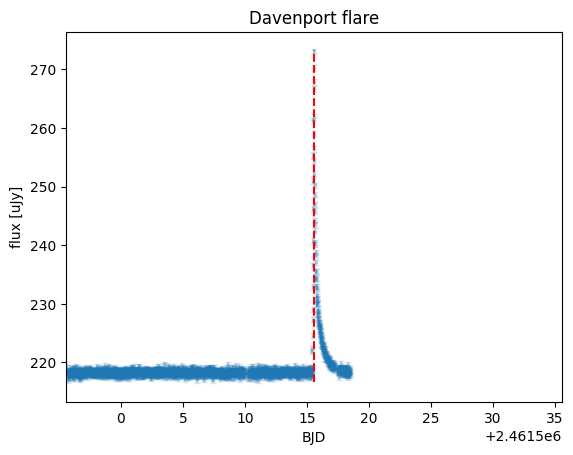

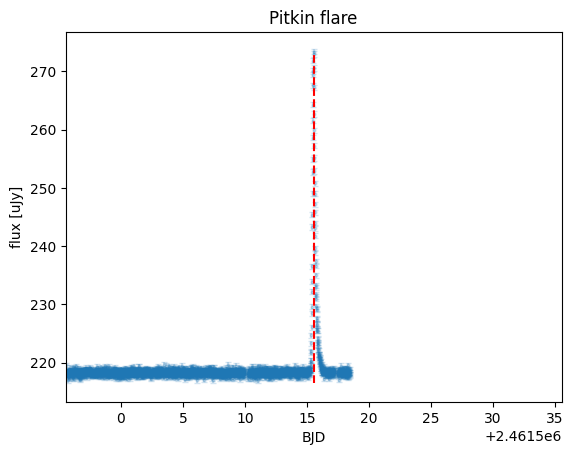

In [53]:
event_obs_davenport = event_obs.loc[event_obs['flare_model']=='davenport']
event_obs_pitkin = event_obs.loc[event_obs['flare_model']=='pitkin']

print("flux excess ratio, davenport: ", event_obs_davenport['peak_excess_uJy'].iloc[0]/event_obs_davenport['baseline_flux_uJy'].iloc[0])
print("flux excess ratio, pitkin: ", event_obs_pitkin['peak_excess_uJy'].iloc[0]/event_obs_pitkin['baseline_flux_uJy'].iloc[0])

plt.errorbar(event_obs_davenport['bjd'], event_obs_davenport['flux_uJy'], event_obs_davenport['flux_err_uJy'], 
             linestyle='', marker='o', markersize=2, capsize=2, alpha=0.2)
plt.xlabel('BJD')
plt.ylabel('flux [uJy]')
plt.xlim([event_obs['peak_bjd'].iloc[0]-20, event_obs['peak_bjd'].iloc[0]+20])
plt.vlines(event_obs['peak_bjd'].iloc[0], min(event_obs['flux_uJy']), max(event_obs['flux_uJy']), linestyle='--', color='r',
          zorder=100)
plt.title('Davenport flare')
plt.show()

plt.errorbar(event_obs_pitkin['bjd'], event_obs_pitkin['flux_uJy'], event_obs_pitkin['flux_err_uJy'], 
             linestyle='', marker='o', markersize=2, capsize=2, alpha=0.2)
plt.xlabel('BJD')
plt.ylabel('flux [uJy]')
plt.xlim([event_obs['peak_bjd'].iloc[0]-20, event_obs['peak_bjd'].iloc[0]+20])
plt.vlines(event_obs['peak_bjd'].iloc[0], min(event_obs['flux_uJy']), max(event_obs['flux_uJy']), linestyle='--', color='r',
          zorder=100)
plt.title('Pitkin flare')
plt.show()

### venti flare

In [47]:
meta_df.loc[meta_df.peak_excess_uJy/meta_df.baseline_flux_uJy > 0.5]

,name,event_id,sim_label,SubRun,Field,EventID,final_weight,ObsGroup_0_chi2,t0lens1,tE_ref,...,extinction_F087,extinction_F213,parent_event_id,flare_model,parent_name,parameter_quality,baseline_flux_uJy,peak_excess_uJy,peak_bjd,fwhm_days
30,RMDC26_004424__flare_davenport,-8849,RMDC26_1S1L_ML,1.0,915.0,2797.0,0.000176,1.038038e+06,2.462917e+06,0.575802,...,1.868099,0.251193,4424,davenport,RMDC26_004424,approximate_pass,23.274466,21.867368,2.462917e+06,0.885985
31,RMDC26_004424__flare_pitkin,-8850,RMDC26_1S1L_ML,1.0,915.0,2797.0,0.000176,1.038038e+06,2.462917e+06,0.575802,...,1.868099,0.251193,4424,pitkin,RMDC26_004424,approximate_pass,23.274466,21.867368,2.462917e+06,0.885985
34,RMDC26_004488__flare_davenport,-8977,RMDC26_1S1L_ML,0.0,876.0,3266.0,0.019870,7.139448e+06,2.462961e+06,2.383826,...,1.639818,0.220497,4488,davenport,RMDC26_004488,approximate_pass,27.872481,86.546475,2.462961e+06,0.675178
35,RMDC26_004488__flare_pitkin,-8978,RMDC26_1S1L_ML,0.0,876.0,3266.0,0.019870,7.139448e+06,2.462961e+06,2.383826,...,1.639818,0.220497,4488,pitkin,RMDC26_004488,approximate_pass,27.872481,86.546475,2.462961e+06,0.675178
52,RMDC26_005096__flare_davenport,-10193,RMDC26_1S1L_ML,1.0,673.0,3714.0,0.001066,2.296950e+04,2.462930e+06,0.140069,...,6.466057,0.869456,5096,davenport,RMDC26_005096,approximate_pass,2.916832,3.910800,2.462930e+06,0.229592
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3519,RMDC26_127947__flare_pitkin,-255896,RMDC26_1S1L_ML,1.0,677.0,351.0,0.000007,4.323377e+06,2.461852e+06,11.957822,...,1.316420,0.177012,127947,pitkin,RMDC26_127947,approximate_pass,27.026080,15.439075,2.461826e+06,7.301718
3522,RMDC26_134188__flare_davenport,-268377,RMDC26_1S1L_ML,0.0,876.0,108.0,0.000677,2.152986e+04,2.462743e+06,0.507490,...,1.639818,0.220497,134188,davenport,RMDC26_134188,approximate_pass,6.970720,3.612227,2.462743e+06,0.400791
3523,RMDC26_134188__flare_pitkin,-268378,RMDC26_1S1L_ML,0.0,876.0,108.0,0.000677,2.152986e+04,2.462743e+06,0.507490,...,1.639818,0.220497,134188,pitkin,RMDC26_134188,approximate_pass,6.970720,3.612227,2.462743e+06,0.400791
3550,RMDC26_233485__flare_davenport,-466971,RMDC26_1S1L_ML,0.0,591.0,9331.0,0.000095,4.197928e+03,2.461666e+06,0.562214,...,7.947981,1.068722,233485,davenport,RMDC26_233485,approximate_pass,0.909685,0.877074,2.461666e+06,0.612427


In [48]:
event_id = 4424

# Reconstruct a single event's lightcurve
event_obs = con.execute(f"""
    SELECT 
        o.event_id,
        m.name,
        e.bjd,
        o.filt,
        o.flux_uJy,
        o.flux_err_uJy,
        m.tE_helio,
        m.sim_label,
        m.flare_model,
        m.parent_event_id,
        m.baseline_flux_uJy,
        m.peak_excess_uJy,
        m.peak_bjd,
        m.fwhm_days
    FROM '{obs_p}' o
    JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
    JOIN '{meta_p}' m ON o.event_id = m.event_id
    WHERE o.parent_event_id = {event_id}
    ORDER BY e.bjd
""").df()

flux excess ratio, davenport:  0.9395432893140578
flux excess ratio, pitkin:  0.9395432893140578


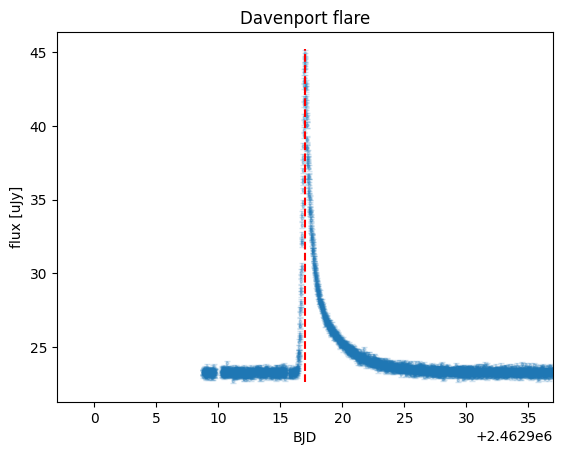

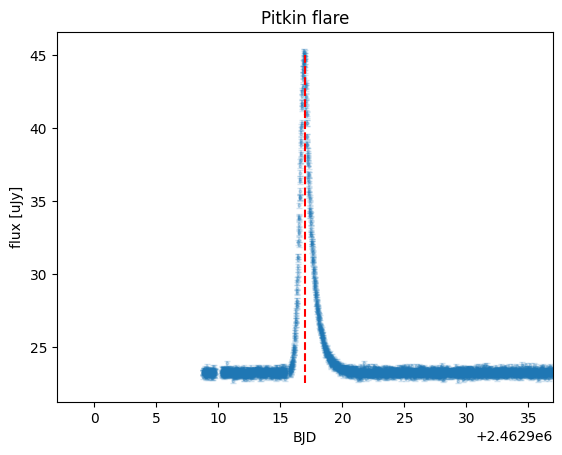

In [49]:
event_obs_davenport = event_obs.loc[event_obs['flare_model']=='davenport']
event_obs_pitkin = event_obs.loc[event_obs['flare_model']=='pitkin']

print("flux excess ratio, davenport: ", event_obs_davenport['peak_excess_uJy'].iloc[0]/event_obs_davenport['baseline_flux_uJy'].iloc[0])
print("flux excess ratio, pitkin: ", event_obs_pitkin['peak_excess_uJy'].iloc[0]/event_obs_pitkin['baseline_flux_uJy'].iloc[0])

plt.errorbar(event_obs_davenport['bjd'], event_obs_davenport['flux_uJy'], event_obs_davenport['flux_err_uJy'], 
             linestyle='', marker='o', markersize=2, capsize=2, alpha=0.2)
plt.xlabel('BJD')
plt.ylabel('flux [uJy]')
plt.xlim([event_obs['peak_bjd'].iloc[0]-20, event_obs['peak_bjd'].iloc[0]+20])
plt.vlines(event_obs['peak_bjd'].iloc[0], min(event_obs['flux_uJy']), max(event_obs['flux_uJy']), linestyle='--', color='r',
          zorder=100)
plt.title('Davenport flare')
plt.show()

plt.errorbar(event_obs_pitkin['bjd'], event_obs_pitkin['flux_uJy'], event_obs_pitkin['flux_err_uJy'], 
             linestyle='', marker='o', markersize=2, capsize=2, alpha=0.2)
plt.xlabel('BJD')
plt.ylabel('flux [uJy]')
plt.xlim([event_obs['peak_bjd'].iloc[0]-20, event_obs['peak_bjd'].iloc[0]+20])
plt.vlines(event_obs['peak_bjd'].iloc[0], min(event_obs['flux_uJy']), max(event_obs['flux_uJy']), linestyle='--', color='r',
          zorder=100)
plt.title('Pitkin flare')
plt.show()
